## How My Spotify Listening Changed (2022–2026)
# 1. Setup and loading the data
# 2. Cleaning
# 3. Top artists and songs
# 4. When I listen: hour of day and day of week
# 5. How my taste changed: genres in 2026
# 6. Bonus: piano at night, and my Korea trip
# 7. Summary and limitations

In [98]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [99]:
import glob
files = sorted(glob.glob("/content/drive/MyDrive/spotify_project/Streaming_History_Audio_*.json"))
print(len(files))
files

18


['/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2020.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2021.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2022.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2022_1.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2022_2.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2023.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2023_1.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2023_2.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2024.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2024_1.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2024_2.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio_2025.json',
 '/content/drive/MyDrive/spotify_project/Streaming_History_Audio

In [100]:
import pandas as pd

first = pd.read_json(files[0])
print(first.shape)
small.head()
first.columns

(3063, 23)


Index(['ts', 'platform', 'ms_played', 'conn_country', 'ip_addr',
       'master_metadata_track_name', 'master_metadata_album_artist_name',
       'master_metadata_album_album_name', 'spotify_track_uri', 'episode_name',
       'episode_show_name', 'spotify_episode_uri', 'audiobook_title',
       'audiobook_uri', 'audiobook_chapter_uri', 'audiobook_chapter_title',
       'reason_start', 'reason_end', 'shuffle', 'skipped', 'offline',
       'offline_timestamp', 'incognito_mode'],
      dtype='object')

In [101]:
cols = ["ts", "master_metadata_track_name", "master_metadata_album_artist_name", "ms_played", "skipped"]
small = first[cols]
print(small.shape)
small.head()

(3063, 5)


,ts,master_metadata_track_name,master_metadata_album_artist_name,ms_played,skipped
0,2020-11-11T19:26:25Z,Mean,$NOT,124986,False
1,2020-11-12T01:38:14Z,Prospect (ft. Lil Baby),iann dior,43544,False
2,2020-11-12T18:27:37Z,10K,KB,169630,False
3,2020-11-12T18:29:38Z,Restore Me,Lecrae,2890,False
4,2020-11-12T18:29:42Z,10K,KB,3660,False


In [102]:
small.isna().sum()

,0
ts,0
master_metadata_track_name,1
master_metadata_album_artist_name,1
ms_played,0
skipped,0


In [103]:
frames = []
for f in files:
  frames.append(pd.read_json(f))
df = pd.concat(frames, ignore_index = True)
print(df.shape)

(253882, 23)


In [104]:
df.duplicated().sum()

np.int64(36)

In [105]:
df = df.drop_duplicates()
print(df.shape)

(253846, 23)


In [106]:
df = df[cols]
print(df.shape)
df.dtypes

(253846, 5)


,0
ts,object
master_metadata_track_name,object
master_metadata_album_artist_name,object
ms_played,int64
skipped,bool


In [107]:
df["ts"] = pd.to_datetime(df["ts"])
df.dtypes

,0
ts,"datetime64[ns, UTC]"
master_metadata_track_name,object
master_metadata_album_artist_name,object
ms_played,int64
skipped,bool


In [108]:
df["ts"] = df["ts"].dt.tz_convert("America/Toronto")
df["ts"].head()

,ts
0,2020-11-11 14:26:25-05:00
1,2020-11-11 20:38:14-05:00
2,2020-11-12 13:27:37-05:00
3,2020-11-12 13:29:38-05:00
4,2020-11-12 13:29:42-05:00


In [109]:
df["ts"].dt.year.value_counts().sort_index()

,count
ts,
2020,3048
2021,13078
2022,47276
2023,41289
2024,43927
2025,60021
2026,45207


In [110]:
listens = df[df["ms_played"] >= 30000]
listens["ts"].dt.year.value_counts().sort_index()

,count
ts,
2020,1092
2021,6771
2022,17328
2023,13360
2024,18123
2025,25519
2026,15439


In [111]:
listens = df[df["ms_played"] >= 60000]
listens["ts"].dt.year.value_counts().sort_index()

,count
ts,
2020,972
2021,6285
2022,15712
2023,12032
2024,16748
2025,23806
2026,14331


In [112]:
listens.isna().sum()

,0
ts,0
master_metadata_track_name,257
master_metadata_album_artist_name,257
ms_played,0
skipped,0


In [113]:
listens = listens.dropna(subset=["master_metadata_track_name"])
print(listens.shape)

(89629, 5)


In [114]:
listens.isna().sum()

,0
ts,0
master_metadata_track_name,0
master_metadata_album_artist_name,0
ms_played,0
skipped,0


In [115]:
listens = listens[listens["ts"].dt.year >= 2022]
print(listens.shape)

(82375, 5)


In [116]:
listens["master_metadata_album_artist_name"].value_counts().head(10)

,count
master_metadata_album_artist_name,
ENHYPEN,4127
Shin Giwon Piano,2942
Drake,1660
BTS,1631
The Weeknd,1256
TWICE,977
Stray Kids,855
LE SSERAFIM,844
Justin Bieber,831


In [117]:
listens_2026 = listens[listens["ts"].dt.year == 2026]

total_minutes = listens_2026["ms_played"].sum() / 1000 / 60
listening_days = listens_2026["ts"].dt.date.nunique()

print(round(total_minutes))
print(listening_days)
print(round(total_minutes / listening_days))
print(round(total_minutes / 295))



48397
284
170
164


In [118]:
listens_2026["master_metadata_album_artist_name"].value_counts().head(10)

,count
master_metadata_album_artist_name,
ENHYPEN,870
BTS,600
Shin Giwon Piano,445
Drake,414
The Weeknd,299
Stray Kids,252
Justin Bieber,233
JUNNY,223
Travis Scott,211


In [119]:
artist_minutes = listens_2026.groupby("master_metadata_album_artist_name")["ms_played"].sum() / 60000
artist_minutes.sort_values(ascending=False).head(10).round()

,ms_played
master_metadata_album_artist_name,
ENHYPEN,2348.0
BTS,2106.0
Shin Giwon Piano,1648.0
Drake,1406.0
The Weeknd,1075.0
Justin Bieber,739.0
JUNNY,738.0
Stray Kids,696.0
Elevation Worship,667.0


In [120]:
listens_2026["master_metadata_track_name"].value_counts().head(10)

,count
master_metadata_track_name,
Knife,58
BTS Cypher Pt.3: Killer,53
Sleep Tight,45
Lost Island,45
Outside,39
No Way Back (Feat. So!YoON!),36
2.0,36
FYA,35
Future Perfect (Pass the MIC),35


In [121]:
song_minutes = listens_2026.groupby("master_metadata_track_name")["ms_played"].sum() / 60000
song_minutes.sort_values(ascending=False).head(10).round()

,ms_played
master_metadata_track_name,
BTS Cypher Pt.3: Killer,228.0
MIC Drop (Steve Aoki Remix) (Full Length Edition),146.0
Knife,131.0
BTS Cypher 4,123.0
Lost Island,122.0
Sleep Tight,121.0
No One,119.0
Blockbuster feat. YEONJUN of TOMORROW X TOGETHER,113.0
THANK GOD I'M FREE,110.0


In [122]:
promise = listens_2026[listens_2026["master_metadata_track_name"] == "Promise"]
(promise.groupby("master_metadata_album_artist_name")["ms_played"].sum() / 60000).round()

,ms_played
master_metadata_album_artist_name,
Choi Yu Ree,36.0
JUNNY,30.0
Jimin,5.0
Laufey,12.0
Park Ki Young,8.0
Shin Giwon Piano,7.0
Wonstein,9.0


In [123]:
song_minutes = listens_2026.groupby(["master_metadata_track_name", "master_metadata_album_artist_name"])["ms_played"].sum() / 60000
song_minutes.sort_values(ascending=False).head(10).round()

,,ms_played
master_metadata_track_name,master_metadata_album_artist_name,
BTS Cypher Pt.3: Killer,BTS,228.0
MIC Drop (Steve Aoki Remix) (Full Length Edition),BTS,146.0
Knife,ENHYPEN,131.0
BTS Cypher 4,BTS,123.0
Lost Island,ENHYPEN,122.0
Sleep Tight,ENHYPEN,121.0
Blockbuster feat. YEONJUN of TOMORROW X TOGETHER,ENHYPEN,113.0
THANK GOD I'M FREE,ELEVATION RHYTHM,110.0
No One,Elevation Worship,109.0


In [124]:
for year in range(2022, 2027):
    one_year = listens[listens["ts"].dt.year == year]
    print(year, one_year["master_metadata_album_artist_name"].value_counts().head(1))

2022 master_metadata_album_artist_name
ENHYPEN    663
Name: count, dtype: int64
2023 master_metadata_album_artist_name
ENHYPEN    701
Name: count, dtype: int64
2024 master_metadata_album_artist_name
Shin Giwon Piano    1298
Name: count, dtype: int64
2025 master_metadata_album_artist_name
ENHYPEN    1219
Name: count, dtype: int64
2026 master_metadata_album_artist_name
ENHYPEN    870
Name: count, dtype: int64


In [125]:
top50 = listens_2026["master_metadata_album_artist_name"].value_counts().head(50)
print(round(top50.sum() / len(listens_2026) * 100))
top50

47


,count
master_metadata_album_artist_name,
ENHYPEN,870
BTS,600
Shin Giwon Piano,445
Drake,414
The Weeknd,299
Stray Kids,252
Justin Bieber,233
JUNNY,223
Travis Scott,211


In [126]:
artist_genre = {
    "ENHYPEN": "K-pop", "BTS": "K-pop", "Stray Kids": "K-pop", "CORTIS": "K-pop",
    "ATEEZ": "K-pop", "LE SSERAFIM": "K-pop", "TWICE": "K-pop", "SEVENTEEN": "K-pop",
    "ILLIT": "K-pop", "IU": "K-pop", "ITZY": "K-pop", "LNGSHOT": "K-pop", "NewJeans": "K-pop",
    "JUNNY": "Korean R&B/hip-hop/indie", "Yerin Baek": "Korean R&B/hip-hop/indie",
    "pH-1": "Korean R&B/hip-hop/indie", "Colde": "Korean R&B/hip-hop/indie", "10CM": "Korean R&B/hip-hop/indie",
    "Drake": "Hip-hop/rap", "Travis Scott": "Hip-hop/rap", "A$AP Rocky": "Hip-hop/rap",
    "The Kid LAROI": "Hip-hop/rap", "Don Toliver": "Hip-hop/rap", "Future": "Hip-hop/rap",
    "Kanye West": "Hip-hop/rap", "Ty Dolla $ign": "Hip-hop/rap", "Post Malone": "Hip-hop/rap",
    "The Weeknd": "R&B", "keshi": "R&B", "Daniel Caesar": "R&B", "SZA": "R&B",
    "Olivia Dean": "R&B", "Luke Chiang": "R&B", "Brent Faiyaz": "R&B", "Chris Brown": "R&B",
    "Justin Bieber": "Pop/indie", "Olivia Rodrigo": "Pop/indie", "Laufey": "Pop/indie",
    "The 1975": "Pop/indie", "wave to earth": "Pop/indie",
    "Elevation Worship": "Christian/worship", "Alex Jean": "Christian/worship",
    "UPCI Music": "Christian/worship", "Indiana Bible College": "Christian/worship",
    "Mark Crowder": "Christian/worship", "Todd Galberth": "Christian/worship",
    "ELEVATION RHYTHM": "Christian/worship",
    "Shin Giwon Piano": "Instrumental/soundtrack", "照井順政": "Instrumental/soundtrack",
    "Alisa Okehazama": "Instrumental/soundtrack",
}
print(len(artist_genre))

50


In [127]:
listens_2026 = listens_2026.copy()
listens_2026["genre"] = listens_2026["master_metadata_album_artist_name"].map(artist_genre).fillna("Unlabeled")
(listens_2026["genre"].value_counts(normalize=True) * 100).round(1)

,proportion
genre,
Unlabeled,53.3
K-pop,18.8
Hip-hop/rap,8.1
R&B,6.3
Instrumental/soundtrack,4.0
Pop/indie,3.3
Korean R&B/hip-hop/indie,3.2
Christian/worship,3.1


In [128]:
month = listens_2026["ts"].dt.month
table = pd.crosstab(month, listens_2026["genre"], normalize="index") * 100
table.round(1)

genre,Christian/worship,Hip-hop/rap,Instrumental/soundtrack,K-pop,Korean R&B/hip-hop/indie,Pop/indie,R&B,Unlabeled
ts,,,,,,,,
1,1.1,7.8,1.4,20.6,4.2,4.1,8.0,52.7
2,2.5,6.1,5.0,19.3,2.0,2.9,8.8,53.4
3,2.5,9.4,6.2,20.7,2.0,2.3,7.2,49.6
4,2.6,10.2,6.3,16.4,1.2,5.8,10.7,46.8
5,3.5,14.8,3.6,19.8,2.1,3.5,6.1,46.5
6,2.5,10.3,2.3,20.0,5.1,3.2,5.5,51.1
7,2.9,7.1,3.5,21.2,5.4,2.9,3.4,53.5
8,6.4,2.6,3.2,19.4,4.5,1.6,1.0,61.3
9,7.8,4.7,3.6,15.3,3.6,1.2,1.6,62.3


In [129]:
labeled = listens_2026[listens_2026["genre"] != "Unlabeled"]
month = labeled["ts"].dt.month
(pd.crosstab(month, labeled["genre"], normalize="index") * 100).round(1)

genre,Christian/worship,Hip-hop/rap,Instrumental/soundtrack,K-pop,Korean R&B/hip-hop/indie,Pop/indie,R&B
ts,,,,,,,
1,2.3,16.6,3.0,43.6,8.9,8.7,17.0
2,5.3,13.1,10.7,41.3,4.4,6.3,18.9
3,4.9,18.7,12.4,41.0,4.0,4.6,14.3
4,4.9,19.1,11.8,30.9,2.3,10.8,20.2
5,6.6,27.7,6.7,37.1,3.9,6.5,11.5
6,5.0,21.1,4.7,41.0,10.4,6.5,11.3
7,6.3,15.3,7.5,45.6,11.6,6.3,7.4
8,16.5,6.7,8.3,50.2,11.7,4.1,2.6
9,20.6,12.3,9.5,40.7,9.5,3.3,4.1


In [130]:
shares = pd.crosstab(labeled["ts"].dt.month, labeled["genre"], normalize="index") * 100
shares["All Korean"] = shares["K-pop"] + shares["Korean R&B/hip-hop/indie"]
shares["All Korean"].round(1)

,All Korean
ts,
1,52.4
2,45.7
3,45.0
4,33.2
5,41.0
6,51.4
7,57.2
8,61.9
9,50.2


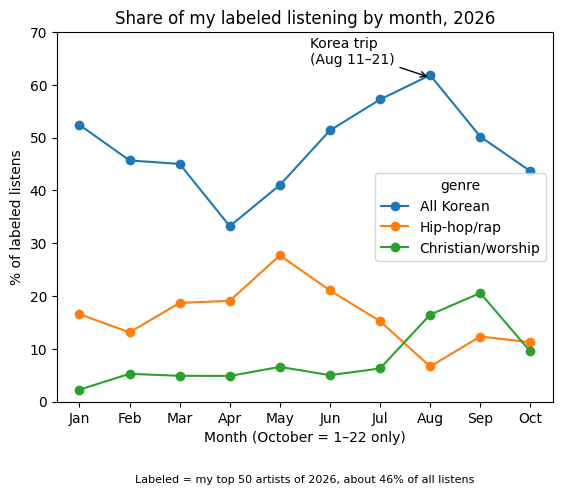

In [131]:
import matplotlib.pyplot as plt

ax = shares[["All Korean", "Hip-hop/rap", "Christian/worship"]].plot(marker="o")
ax.set_title("Share of my labeled listening by month, 2026")
ax.set_xlabel("Month (October = 1–22 only)")
ax.set_ylabel("% of labeled listens")
ax.set_ylim(0, 70)
ax.set_xticks(range(1, 11))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"])
plt.savefig("genre_share_2026.png", dpi=150, bbox_inches="tight")
ax.annotate("Korea trip\n(Aug 11–21)",
            xy=(8, 61.4), xytext=(5.6, 64),
            arrowprops=dict(arrowstyle="->"))
ax.text(0.5, -0.22, "Labeled = my top 50 artists of 2026, about 46% of all listens",
        transform=ax.transAxes, ha="center", fontsize=8)
plt.savefig("genre_share_2026.png", dpi=150, bbox_inches="tight")
plt.show()

In [132]:
listens_2026["ts"].dt.hour.value_counts().sort_index()

,count
ts,
0,616
1,532
2,474
3,525
4,495
5,380
6,313
7,241
8,190


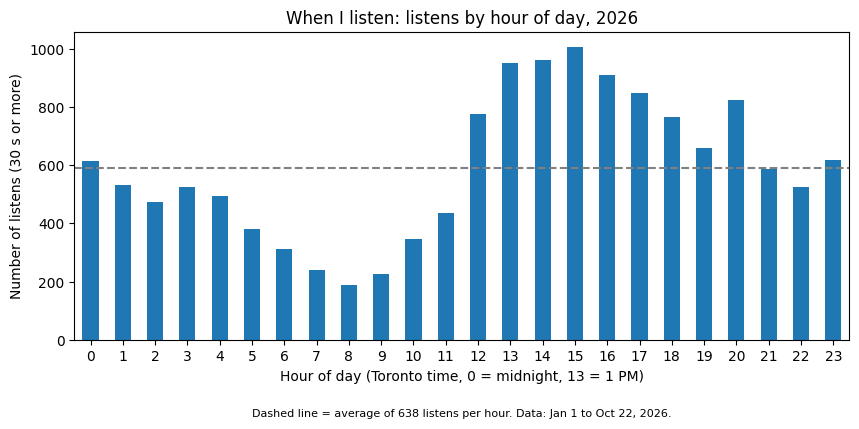

In [133]:
hours = listens_2026["ts"].dt.hour.value_counts().sort_index()

ax = hours.plot(kind = "bar", rot = 0, figsize = (10, 4))
ax.axhline(hours.mean(), color = "gray", linestyle = "--")
ax.set_title("When I listen: listens by hour of day, 2026")
ax.set_xlabel("Hour of day (Toronto time, 0 = midnight, 13 = 1 PM)")
ax.set_ylabel("Number of listens (30 s or more)")
ax.text(0.5, -0.25, "Dashed line = average of 638 listens per hour. Data: Jan 1 to Oct 22, 2026.",
        transform=ax.transAxes, ha="center", fontsize=8)
plt.savefig("listens_by_hour_2026.png", dpi=150, bbox_inches="tight")
plt.show()

In [134]:
days = listens_2026["ts"].dt.day_name().value_counts()
days

,count
ts,
Monday,2310
Tuesday,2157
Friday,2138
Wednesday,2118
Thursday,1872
Saturday,1848
Sunday,1762


In [135]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
days = days.reindex(order)

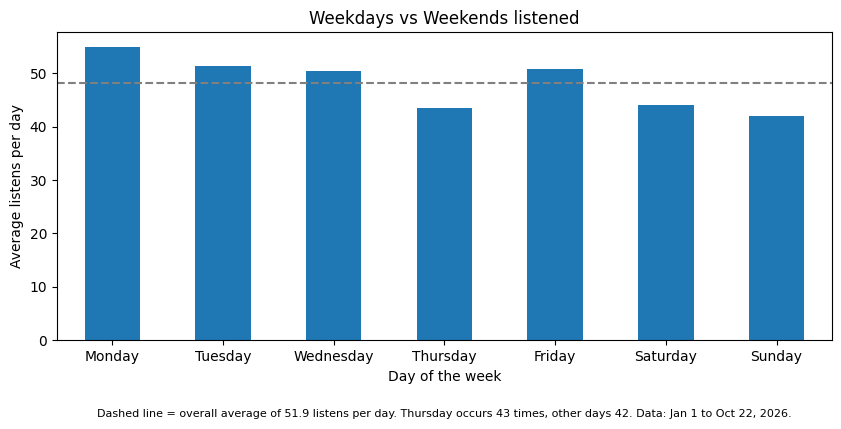

In [136]:
days = listens_2026["ts"].dt.day_name().value_counts()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
days = days.reindex(order)
n_days = pd.Series([42, 42, 42, 43, 42, 42, 42], index=order)
per_day = days / n_days

ax = per_day.plot(kind = "bar", rot = 0, figsize = (10, 4))
ax.axhline(per_day.mean(), color = "gray", linestyle = "--")
ax.set_title("Weekdays vs Weekends listened")
ax.set_xlabel("Day of the week")
ax.set_ylabel("Average listens per day")
ax.text(0.5, -0.25, "Dashed line = overall average of 51.9 listens per day. Thursday occurs 43 times, other days 42. Data: Jan 1 to Oct 22, 2026.",
        transform=ax.transAxes, ha="center", fontsize=8)
plt.savefig("listens_by_weekday_2026.png", dpi=150, bbox_inches="tight")
plt.show()

In [137]:
hour = listens_2026["ts"].dt.hour
is_piano = listens_2026["master_metadata_album_artist_name"] == "Shin Giwon Piano"
(is_piano.groupby(hour).mean() * 100).round(1)

,master_metadata_album_artist_name
ts,
0,1.6
1,3.9
2,5.1
3,6.5
4,4.6
5,3.7
6,7.7
7,7.9
8,14.2


In [138]:
aug = labeled[labeled["ts"].dt.month == 8]
during = aug["ts"].dt.day.between(11, 21)
korean = aug["genre"].isin(["K-pop", "Korean R&B/hip-hop/indie"])

print(during.value_counts())
(korean.groupby(during).mean() * 100).round(1)

ts
False    357
True     183
Name: count, dtype: int64


,genre
ts,
False,59.7
True,66.1


In [139]:
(pd.crosstab(during, aug["genre"], normalize="index") * 100).round(1)

genre,Christian/worship,Hip-hop/rap,Instrumental/soundtrack,K-pop,Korean R&B/hip-hop/indie,Pop/indie,R&B
ts,,,,,,,
False,22.7,6.4,6.7,53.5,6.2,2.0,2.5
True,4.4,7.1,11.5,43.7,22.4,8.2,2.7
